In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

In [43]:
# Data importation

data =  pd.read_excel("C:\\Users\\Ulysse K\\cardio prediction\\data\\raw\\cardio.xlsx")
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [44]:
# Ajustements of the data

## suppression of the id column
data = data.drop('id', axis=1)

data


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,17474,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
69995,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,22431,1,163,72.0,135,80,1,2,0,0,0,1


In [45]:
# age data ajustement
data['age'] = data['age'].apply(lambda x: x//365)

data

,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,50,2,168,62.0,110,80,1,1,0,0,1,0
1,55,1,156,85.0,140,90,3,1,0,0,1,1
2,51,1,165,64.0,130,70,3,1,0,0,0,1
3,48,2,169,82.0,150,100,1,1,0,0,1,1
4,47,1,156,56.0,100,60,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...
69995,52,2,168,76.0,120,80,1,1,1,0,1,0
69996,61,1,158,126.0,140,90,2,2,0,0,1,1
69997,52,2,183,105.0,180,90,3,1,0,1,0,1
69998,61,1,163,72.0,135,80,1,2,0,0,0,1


Data Viz


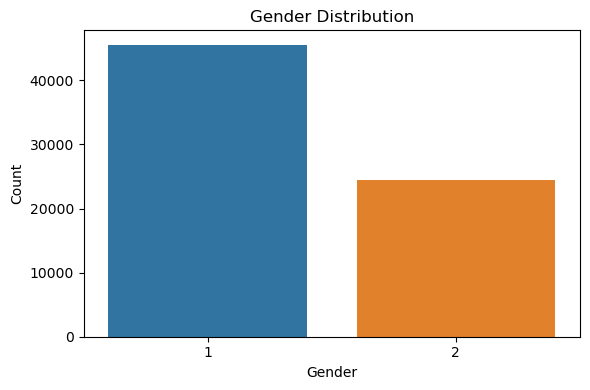

In [46]:
# Gender distribution

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='gender', data=data, ax=ax)
ax.set_title('Gender Distribution')
ax.set_xlabel('Gender')
ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

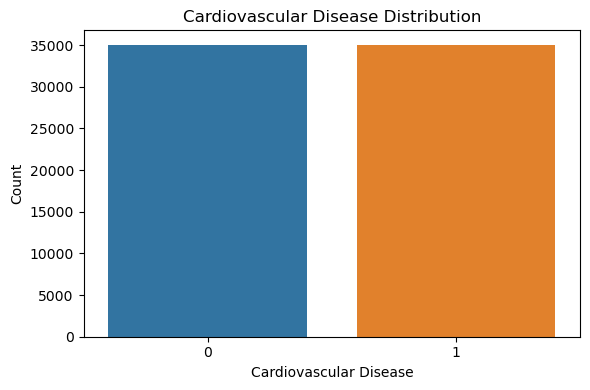

In [47]:
# Cardiovascular disease distribution

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='cardio', data=data, ax=ax)
ax.set_title('Cardiovascular Disease Distribution')
ax.set_xlabel('Cardiovascular Disease')
ax.set_ylabel('Count')
plt.tight_layout()
plt.show()

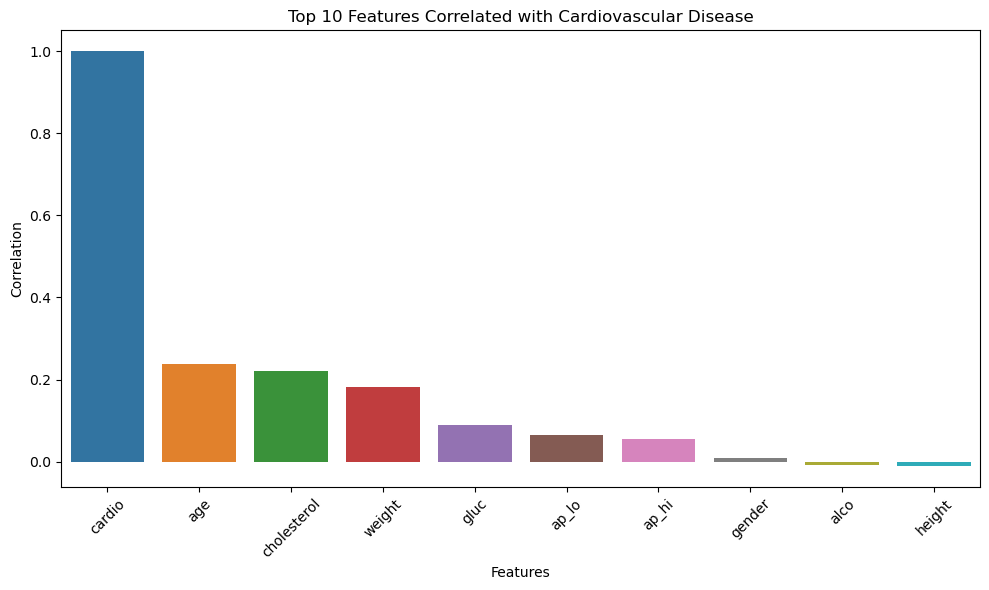

In [48]:
# top 10 features correlated with the target variable

top_features = data.corr()['cardio'].sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_features.index, y=top_features.values)
plt.title('Top 10 Features Correlated with Cardiovascular Disease')
plt.xlabel('Features')
plt.ylabel('Correlation')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



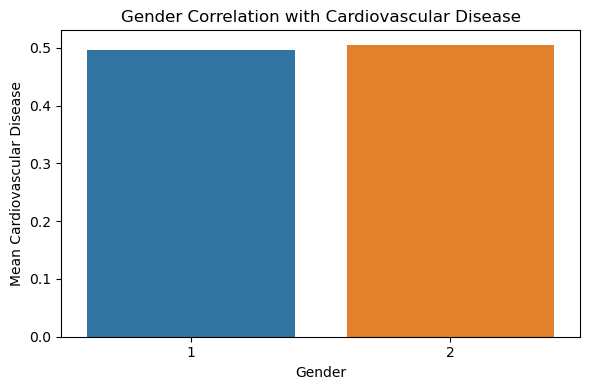

In [49]:
# Gender correlation with cardiovascular disease

gender_cardio_corr = data.groupby('gender')['cardio'].mean().nlargest(2)

plt.figure(figsize=(6, 4))
sns.barplot(x=gender_cardio_corr.index, y=gender_cardio_corr.values)
plt.title('Gender Correlation with Cardiovascular Disease')
plt.xlabel('Gender')
plt.ylabel('Mean Cardiovascular Disease')
plt.tight_layout()
plt.show()


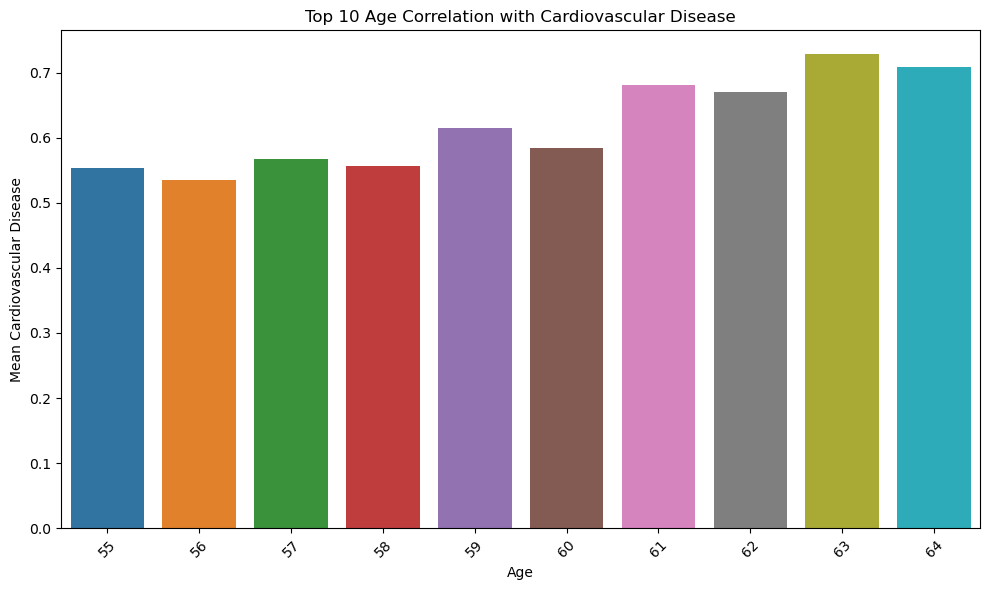

In [50]:
# Top 10 Age correlation with cardiovascular disease

age_cardio_corr = data.groupby('age')['cardio'].mean().nlargest(10).sort_index(ascending=True)

plt.figure(figsize=(10, 6))
sns.barplot(x=age_cardio_corr.index, y=age_cardio_corr.values)
plt.title('Top 10 Age Correlation with Cardiovascular Disease')
plt.xlabel('Age')
plt.ylabel('Mean Cardiovascular Disease')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



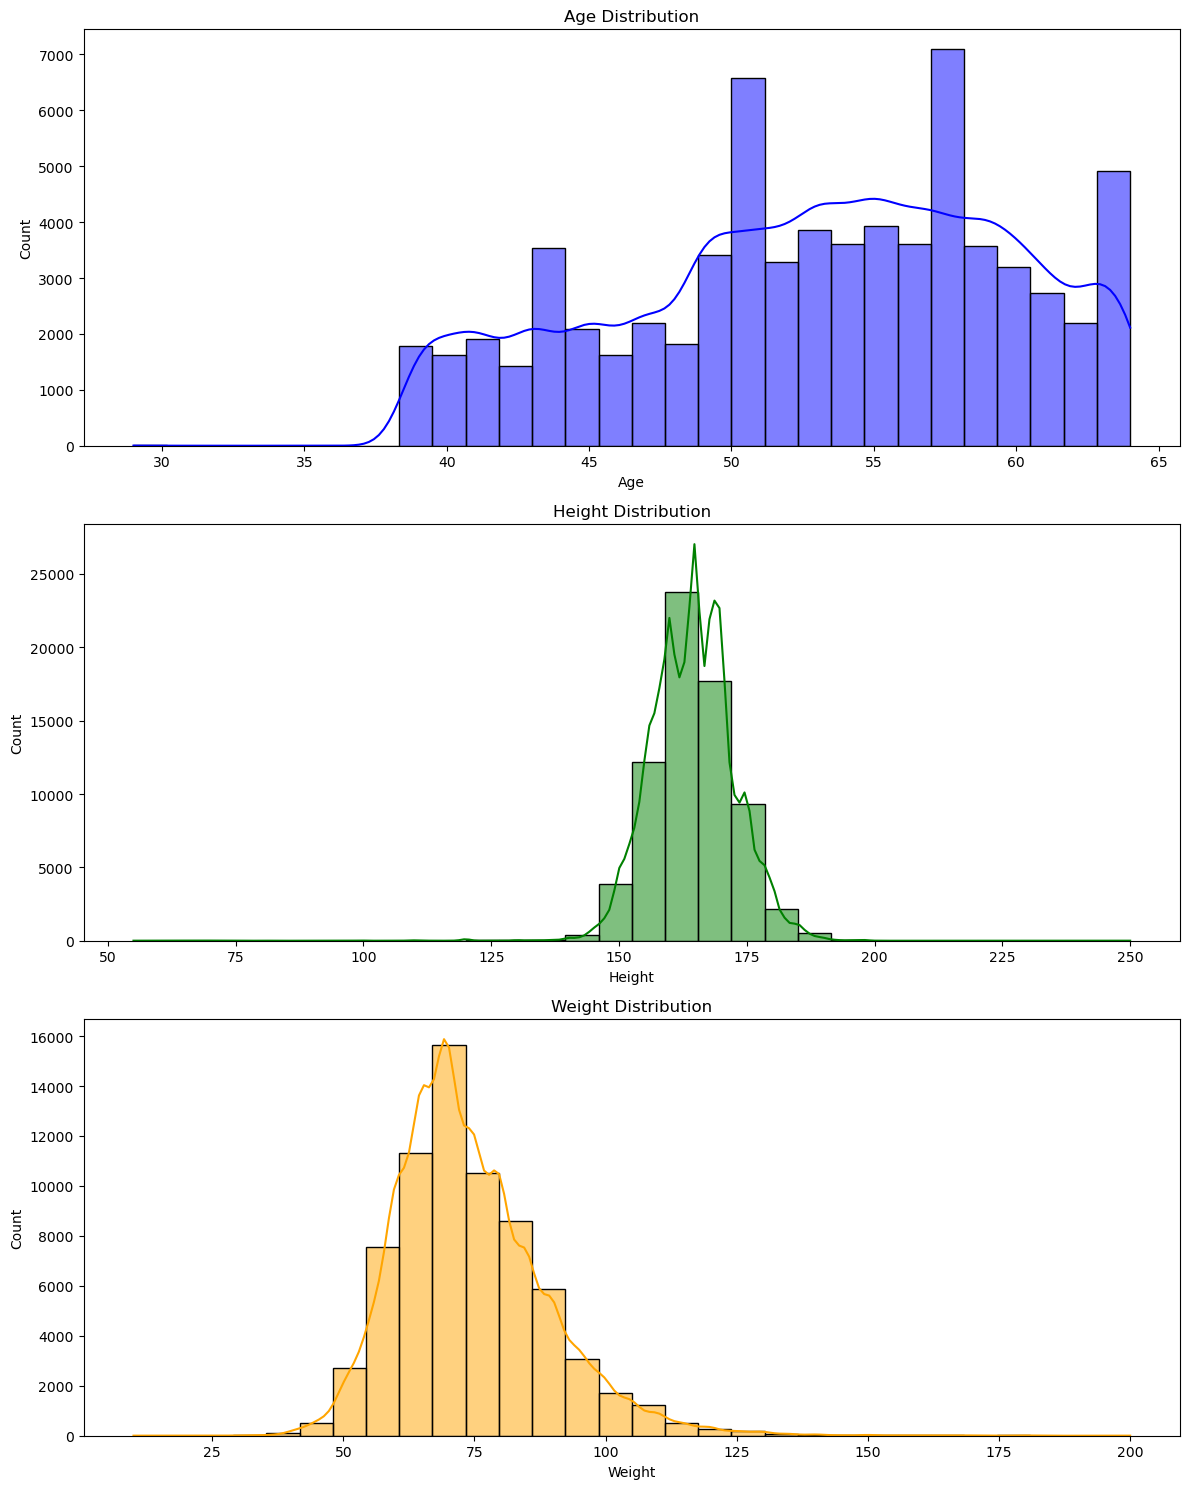

In [51]:
### Visualization of the distribution of numerical features ( age - height - weight) using histograms

fig, ax = plt.subplots(3, 1, figsize=(12, 15))

# Histogram for Age
sns.histplot(data['age'], bins=30, kde=True, ax=ax[0], color='blue')
ax[0].set_title('Age Distribution')
ax[0].set_xlabel('Age')

# Histogram for Height
sns.histplot(data['height'], bins=30, kde=True, ax=ax[1], color='green')
ax[1].set_title('Height Distribution')
ax[1].set_xlabel('Height')

# Histogram for Weight
sns.histplot(data['weight'], bins=30, kde=True, ax=ax[2], color='orange')
ax[2].set_title('Weight Distribution')
ax[2].set_xlabel('Weight')

plt.tight_layout()
plt.show()
